## Fuente de datos inicial

### Conexión a la fuente de datos

In [6]:
# =============================================================================
# 1.1 Importar librerías
# =============================================================================
# Rutas globales y paquetes python
import sys
from pathlib import Path

from configparser import ConfigParser
from datetime import datetime

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn - Preprocessing
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Sklearn - Feature Selection
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

#--- Configuración de visualización ---#
from IPython.display import display, Markdown
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
plt.style.use('seaborn-v0_8-whitegrid')

# Agregar 'src' al path para importar módulos del proyecto
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.db.connection import PostgresConnection

print(f"✓ Librerías importadas correctamente")
print(f"✓ Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

✓ Librerías importadas correctamente
✓ Fecha de ejecución: 2026-08-19 11:11:52


In [8]:
# =============================================================================
# 1.2 Establecer conexión a PostgreSQL
# =============================================================================
config_path = project_root / 'configs' / 'database.ini'

config = ConfigParser()
config.read(config_path)

pg_conn = PostgresConnection(
    host=config.get('postgres', 'host'),
    port=config.getint('postgres', 'port'),
    dbname=config.get('postgres', 'dbname'),
    user=config.get('postgres', 'user'),
    password=config.get('postgres', 'password')
)
conn = pg_conn.connect()

print(f"✓ Conexión establecida exitosamente")
print(f"  Base de datos: {pg_conn.dbname}")
print(f"  Host: {pg_conn.host}:{pg_conn.port}")

✓ Conexión establecida exitosamente
  Base de datos: postgres
  Host: localhost:5432


In [9]:
# =============================================================================
# 1.3 Cargar datos desde la capa Silver
# =============================================================================
TABLA_ORIGEN = "r$_ds_obras_publicas_infobras"

query = f"SELECT * FROM {TABLA_ORIGEN}"
df_raw = pd.read_sql(query, conn)

print(f"  Datos cargados desde: {TABLA_ORIGEN}")
print(f"  - Registros: {len(df_raw):,}")
print(f"  - Columnas: {len(df_raw.columns)}")
print(f"  - Memoria: {df_raw.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

C:\Users\yanfr\AppData\Local\Temp\ipykernel_16208\739730419.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_raw = pd.read_sql(query, conn)


  Datos cargados desde: r$_ds_obras_publicas_infobras
  - Registros: 69,952
  - Columnas: 130
  - Memoria: 284.56 MB


### 1. Filtros funcionales

In [10]:
# =============================================================================
# 1.4 Filtrar por Nivel de Gobierno
# =============================================================================

# Configuración del filtro
NIVEL_GOBIERNO_FILTRO = 'GOBIERNO NACIONAL'  # Opciones: 'GOBIERNO NACIONAL', 'GOBIERNO REGIONAL', 'GOBIERNO LOCAL'
MARCO = 'INVIERTE'

# Verificar valores únicos antes del filtro
print("Distribución por Nivel de Gobierno (antes del filtro)")
print("=" * 60)
print(df_raw['nivel_gobierno'].value_counts())
print()

# Aplicar filtro
df = df_raw[(df_raw['nivel_gobierno'] == NIVEL_GOBIERNO_FILTRO) & (df_raw['marco'] == MARCO)].copy()

print(f"Filtro aplicado: nivel_gobierno == '{NIVEL_GOBIERNO_FILTRO}'")
print(f"Filtro aplicado: marco == '{MARCO}'")
print(f" - Registros después del filtro: {len(df):,}")

# Verificar distribución del target después del filtro
if 'flg_opa_incumplimiento_contractual' in df_raw.columns:
    print(f"\nDistribución del target después del filtro:")
    print(df['flg_opa_incumplimiento_contractual'].value_counts())
    print(f"  Tasa de paralización: {df['flg_opa_incumplimiento_contractual'].mean()*100:.2f}%")

Distribución por Nivel de Gobierno (antes del filtro)
nivel_gobierno
GOBIERNO LOCAL       55582
GOBIERNO NACIONAL     7367
GOBIERNO REGIONAL     6998
Name: count, dtype: int64

Filtro aplicado: nivel_gobierno == 'GOBIERNO NACIONAL'
Filtro aplicado: marco == 'INVIERTE'
 - Registros después del filtro: 2,646

Distribución del target después del filtro:
flg_opa_incumplimiento_contractual
0    2449
1     197
Name: count, dtype: int64
  Tasa de paralización: 7.45%


In [11]:
#print(*df.columns, sep="\n")
for col in df.columns:
    print(f"{col}: {df[col].dtype}, Nulos: {df[col].isnull().sum()}, Únicos: {df[col].nunique()}")

codigo_entidad: str, Nulos: 0, Únicos: 165
entidad_publica: str, Nulos: 0, Únicos: 165
codigo_infobras: int64, Nulos: 0, Únicos: 2646
nombre_obra: str, Nulos: 0, Únicos: 2635
modalidad_ejecucion_obra: str, Nulos: 0, Únicos: 1
flg_corresponde_saldo_obra: bool, Nulos: 0, Únicos: 2
codigo_infobras_obra_inicial: float64, Nulos: 2559, Únicos: 83
naturaleza_obra: str, Nulos: 0, Únicos: 14
tipo_obra_nivel_1: str, Nulos: 0, Únicos: 9
tipo_obra_nivel_2: str, Nulos: 0, Únicos: 36
tipo_obra_nivel_3: str, Nulos: 0, Únicos: 66
estado_ejecucion: str, Nulos: 0, Únicos: 3
flg_reconstruccion_con_cambios: bool, Nulos: 0, Únicos: 2
flg_reactivacion_economica: bool, Nulos: 0, Únicos: 1
otra_marca: object, Nulos: 2646, Únicos: 0
n_informes_monitores_ciudadanos: int64, Nulos: 0, Únicos: 1
n_denuncias_viculadas: object, Nulos: 2646, Únicos: 0
n_informes_control: int64, Nulos: 0, Únicos: 24
n_comentarios_ciudadanos: int64, Nulos: 0, Únicos: 3
flg_obra_caracter_reservado: bool, Nulos: 0, Únicos: 1
nivel_gobier

### 2. Pre-seleccion de variables

In [12]:
# Definir la lista de columnas relevantes
columnas_interes = ['codigo_entidad' # Entidad
                    , 'nivel_gobierno'
                    , 'sector_entidad'
                    , 'codigo_unico' # Proyecto
                    , 'marco'
                    , 'tipo_formato'
                    , 'des_tipo_formato'
                    , 'n_obras_relacionadas_proyecto'
                    , 'codigo_infobras' # Obra
                    , 'modalidad_ejecucion_obra'
                    , 'estado_ejecucion'
                    , 'naturaleza_obra'
                    , 'tipo_obra_nivel_1'
                    , 'tipo_obra_nivel_2'
                    , 'tipo_obra_nivel_3'
                    , 'departamento' # Ubigeo
                    , 'provincia'
                    , 'distrito'
                    , 'fecha_aprobacion_expediente'
                    , 'monto_aprobacion_et'
                    , 'monto_aprobado_soles'
                    , 'colegiatura_1' # Supervisor
                    , 'colegiatura_2' # Residente
# Campos calculados de interes
                    , 'tasa_paralizacion_entidad'
                    , 'n_obras_x_entidad'
                    , 'monto_aprobado_soles_promedio_entidad'
                    , 'tasa_paralizacion_departamento'
                    , 'tasa_paralizacion_tipo_obra_nivel_1'
                    , 'flg_opa_incumplimiento_contractual'
                    , 'fecha_inicio_obra'
                    ]

# Crear el nuevo dataset reducido
df_reducido = df[columnas_interes].copy()

### 3. Analisis de valores faltantes

#### Reporte de valores nulos

In [13]:
from src.eda import missing_values_report

missing_report = missing_values_report(df_reducido)

In [14]:
display(Markdown(missing_report.to_markdown()))

|                                |   missing_count |   missing_percentage |
|:-------------------------------|----------------:|---------------------:|
| colegiatura_1                  |            2646 |               100    |
| des_tipo_formato               |              95 |                 3.59 |
| tipo_formato                   |              95 |                 3.59 |
| colegiatura_2                  |              91 |                 3.44 |
| monto_aprobado_soles           |              18 |                 0.68 |
| monto_aprobacion_et            |              18 |                 0.68 |
| fecha_aprobacion_expediente    |              18 |                 0.68 |
| departamento                   |               1 |                 0.04 |
| distrito                       |               1 |                 0.04 |
| provincia                      |               1 |                 0.04 |
| tasa_paralizacion_departamento |               1 |                 0.04 |

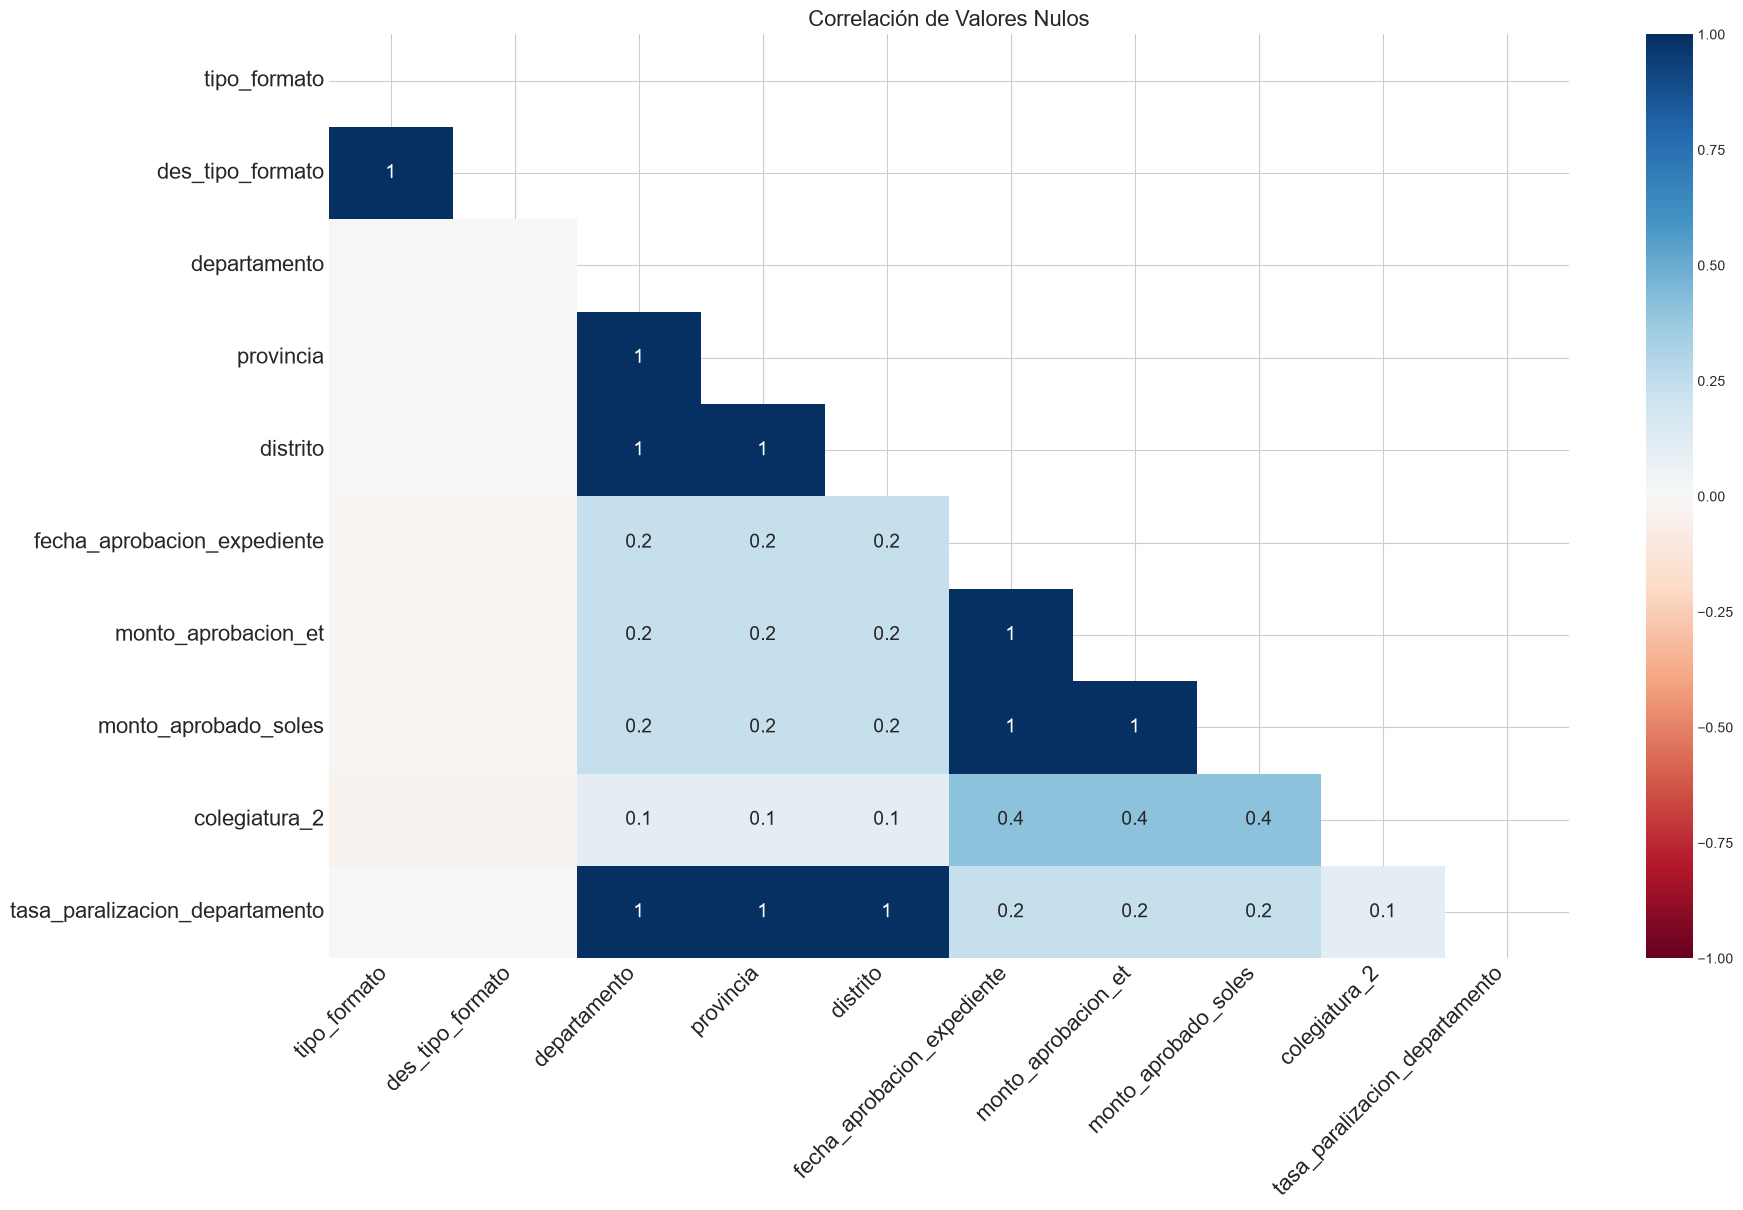

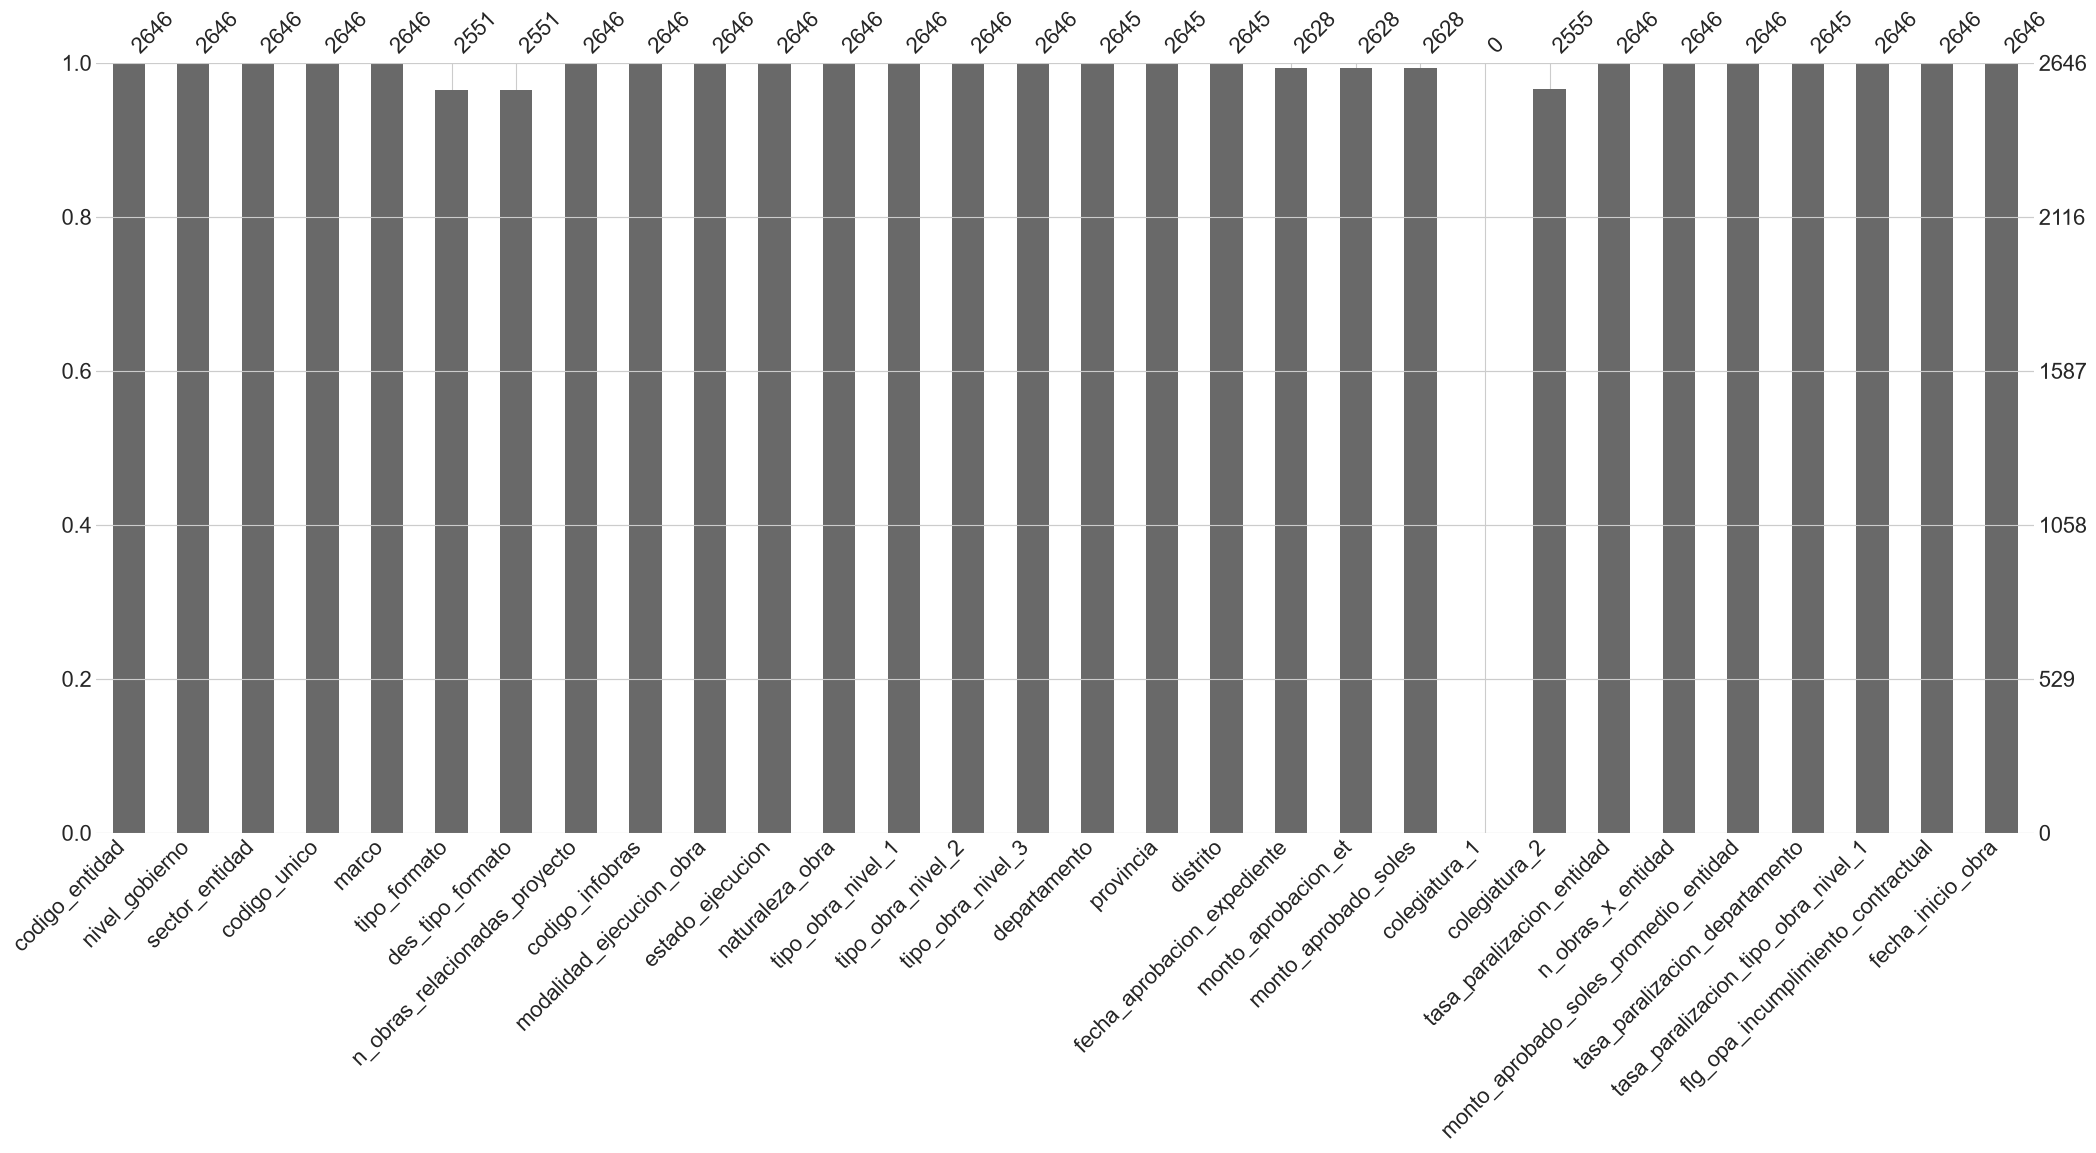

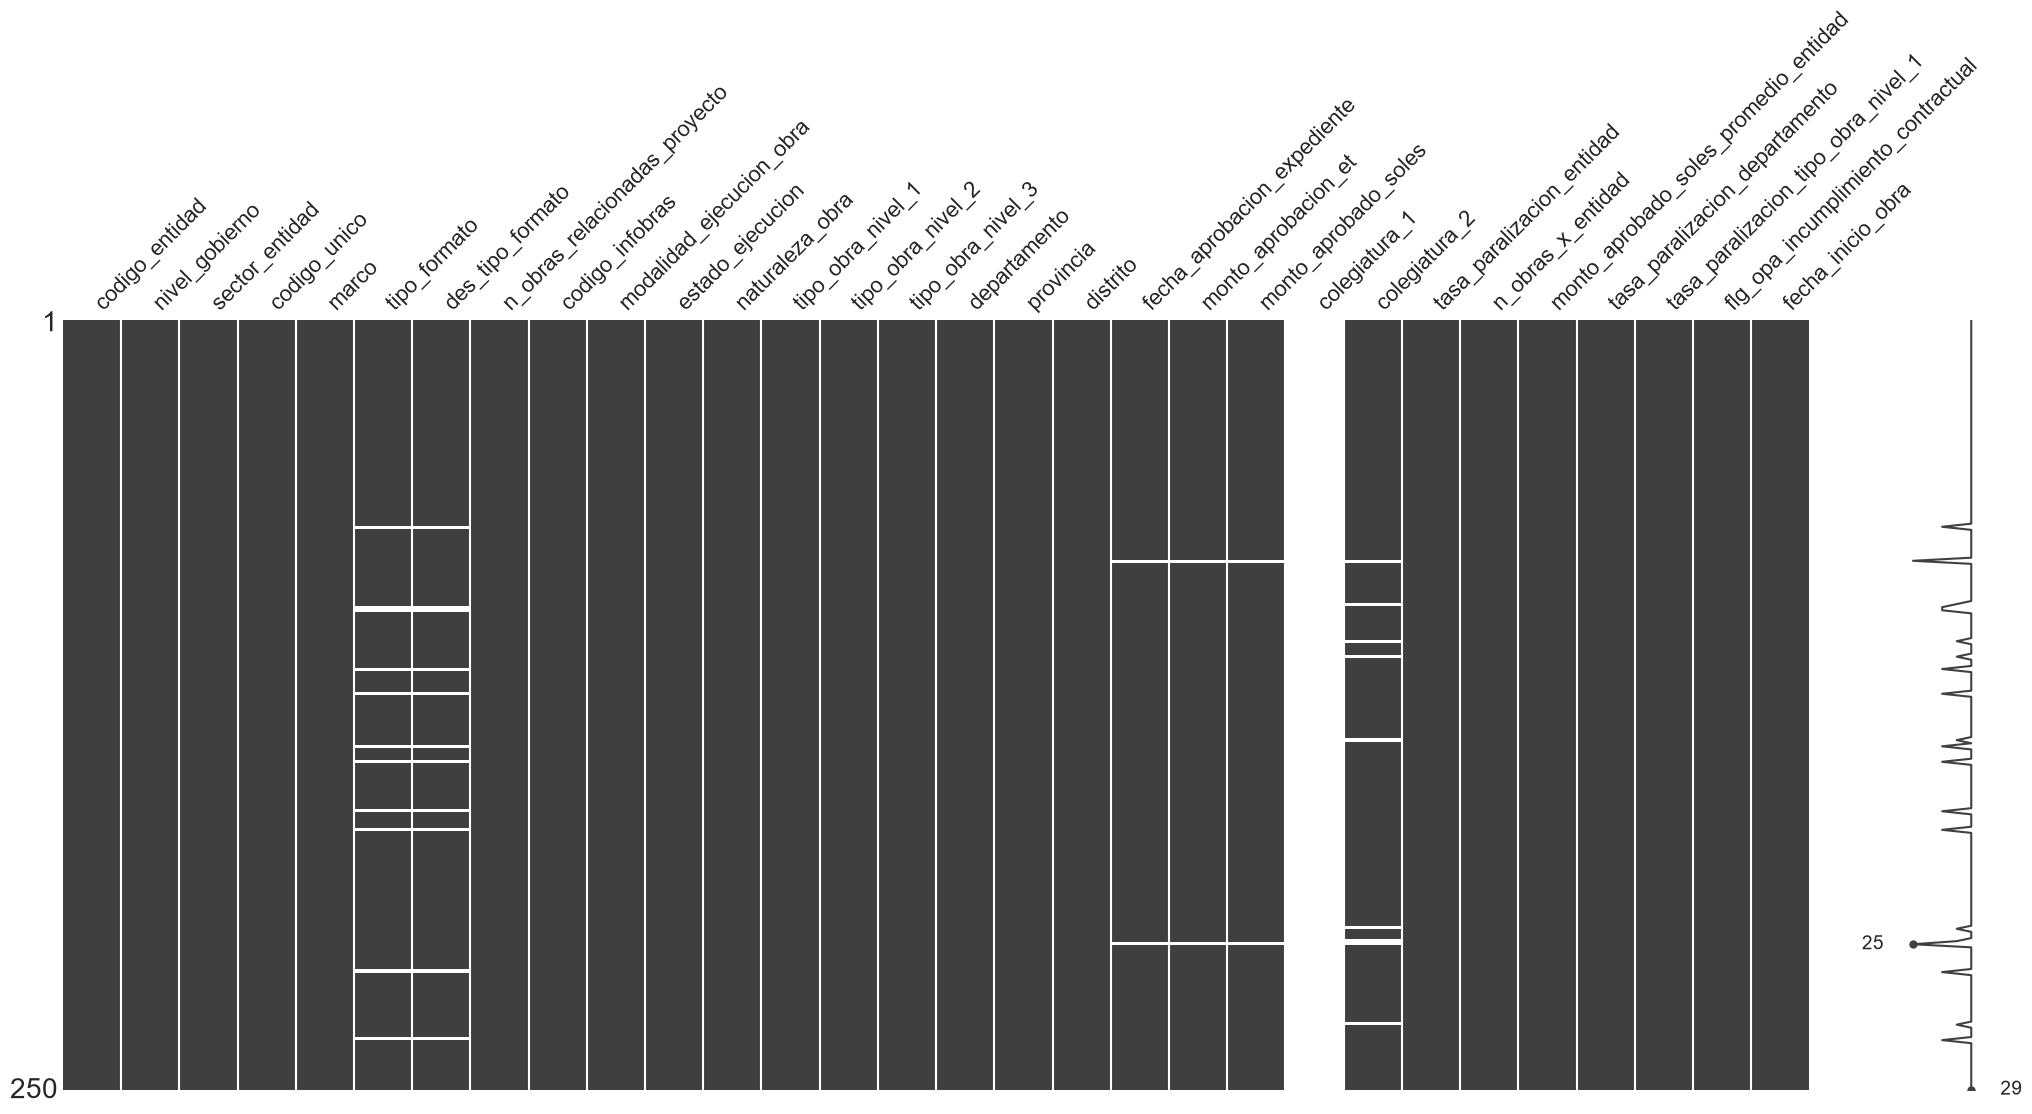

In [15]:
import missingno as msno
import matplotlib.pyplot as plt

# Matriz de calor: Muestra la correlación de nulidad entre columnas (-1 a 1)
# Un valor de 1 significa que si falta una variable, la otra siempre faltará también.
msno.heatmap(df_reducido)
plt.title("Correlación de Valores Nulos", fontsize=16)
plt.show()

# Gráfico de barras de completitud: Muestra visualmente qué tan llenas están las columnas
msno.bar(df_reducido)
plt.show()

msno.matrix(df_reducido.sample(250)) 
plt.show()

#### 3.1. Analisis del campo `monto_aprobado_soles`

In [16]:
df_reducido.loc[df_reducido['monto_aprobado_soles'].isnull()
                , ['monto_aprobado_soles', 'flg_opa_incumplimiento_contractual']]

,monto_aprobado_soles,flg_opa_incumplimiento_contractual
4005,NaN,0
13925,NaN,0
24326,NaN,0
26247,NaN,0
28603,NaN,0
41243,NaN,0
41817,NaN,0
46958,NaN,0
47206,NaN,0
48022,NaN,0


##### Eliminamos los valores nulos de `monto_aprobado_soles`

- Esto debido a que solo impacta en la clase mayoritaria `0`

In [17]:
df_invierte_nacional = df_reducido.dropna(subset=['monto_aprobado_soles'])

#### Analisis de otros campos con valores nulos

In [18]:
missing_report_2 = missing_values_report(df_invierte_nacional)
display(missing_report_2)

,missing_count,missing_percentage
colegiatura_1,2628,100.00
tipo_formato,95,3.61
des_tipo_formato,95,3.61
colegiatura_2,74,2.82


In [19]:
df_invierte_nacional[['colegiatura_2', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, normalize=True, sort=False)

colegiatura_2  flg_opa_incumplimiento_contractual
C I P          0                                     0.834094
C A P          0                                     0.055175
C I P          1                                     0.073440
C A P          1                                     0.001522
No aplica      0                                     0.006849
NaN            0                                     0.028158
R N A          0                                     0.000761
Name: proportion, dtype: float64

In [20]:
df_invierte_nacional[['des_tipo_formato', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, normalize=True, sort=False)

des_tipo_formato       flg_opa_incumplimiento_contractual
INVERSIONES IOARR      0                                     0.351218
NaN                    0                                     0.033105
INTERVENCIONES IRI     0                                     0.229452
PROYECTO DE INVERSION  0                                     0.311263
INTERVENCIONES IRI     1                                     0.039193
INVERSIONES IOARR      1                                     0.013318
PROYECTO DE INVERSION  1                                     0.019406
NaN                    1                                     0.003044
Name: proportion, dtype: float64

findfont: Failed to find font weight medium, now using 400.


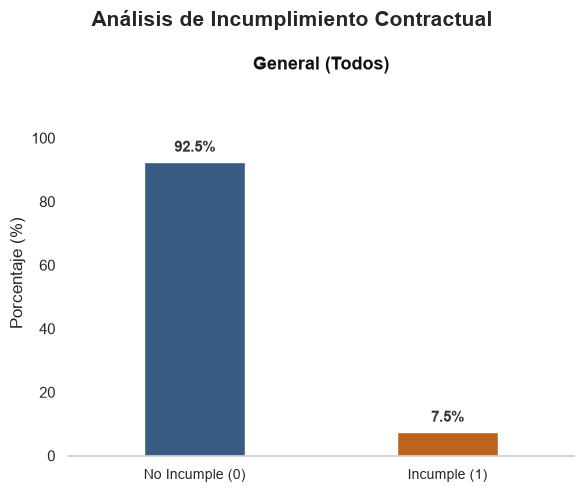

In [21]:
# --- 1. PREPARACIÓN DE DATOS ---
# Calculamos la distribución general
df_aux = df_invierte_nacional['flg_opa_incumplimiento_contractual'].value_counts(normalize=True).reset_index()
df_aux.columns = ['Clase', 'Porcentaje']
df_aux['Porcentaje'] = df_aux['Porcentaje'] * 100  # Convertir a base 100

# --- 2. CONFIGURACIÓN DEL LIENZO (Un solo gráfico) ---
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6, 5))  # Dimensiones optimizadas para una figura única

# Paleta de colores (Azul para 0, Naranja para 1)
colors = {0: '#2b5c8f', 1: '#d95f02'}

# --- 3. GENERACIÓN DEL GRÁFICO ---
bars = sns.barplot(
    x='Clase', 
    y='Porcentaje', 
    data=df_aux, 
    palette=colors, 
    hue='Clase', 
    legend=False,
    width=0.4,  # Ancho estilizado para las dos barras
    ax=ax
)

# Añadimos las etiquetas de porcentaje sobre cada barra
for bar in bars.patches:
    height = bar.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.1f}%',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha='center', va='bottom', 
            fontsize=11, fontweight='bold', color='#333333'
        )
        
# Estética del gráfico (Limpieza visual)
ax.set_title('General (Todos)', fontsize=13, fontweight='bold', pad=15, color='#111111')
ax.set_xlabel('')
ax.set_ylabel('Porcentaje (%)', fontsize=12, fontweight='medium')

# Eliminar bordes innecesarios
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#cccccc')

# Ajustar etiquetas del eje X de forma segura
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Incumple (0)', 'Incumple (1)'], fontsize=10)

# Ajustes globales
plt.ylim(0, 115)  # Espacio superior para las etiquetas
plt.suptitle('Análisis de Incumplimiento Contractual', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


In [22]:
df_invierte_nacional['flg_opa_incumplimiento_contractual'].value_counts()

flg_opa_incumplimiento_contractual
0    2431
1     197
Name: count, dtype: int64

### 4. Pre-tratamiento de outliers

#### 4.1. Funcion para analisis de outliers (Var numerica Vs Target Binario)

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analizar_outliers_monto_vs_target(
    df: pd.DataFrame,
    col_monto: str = "monto_aprobado_soles",
    col_target: str = "flg_opa_incumplimiento_contractual"
):
    data = df[[col_monto, col_target]].copy()

    # Asegurar numérico
    data[col_monto] = pd.to_numeric(data[col_monto], errors="coerce")

    # Eliminar nulos para el análisis
    data = data.dropna(subset=[col_monto, col_target])

    print("=== RESUMEN GENERAL ===")
    print(data[col_monto].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

    print("\n=== RESUMEN POR TARGET ===")
    resumen_target = data.groupby(col_target)[col_monto].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    )
    print(resumen_target)

    # IQR general
    q1 = data[col_monto].quantile(0.25)
    q3 = data[col_monto].quantile(0.75)
    iqr = q3 - q1

    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    data["es_outlier_iqr"] = (
        (data[col_monto] < limite_inf) |
        (data[col_monto] > limite_sup)
    )

    print("\n=== OUTLIERS POR IQR ===")
    print(f"Límite inferior: {limite_inf:,.2f}")
    print(f"Límite superior: {limite_sup:,.2f}")
    print(data["es_outlier_iqr"].value_counts())

    print("\n=== OUTLIERS POR TARGET ===")
    print(pd.crosstab(data[col_target], data["es_outlier_iqr"], normalize="index") * 100)

    # Gráficos
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.boxplot(data=data, x=col_target, y=col_monto, ax=axes[0])
    axes[0].set_title("Monto aprobado por target")
    axes[0].set_xlabel(col_target)
    axes[0].set_ylabel(col_monto)

    sns.boxplot(data=data, x=col_target, y=np.log1p(data[col_monto]), ax=axes[1])
    axes[1].set_title("Log(1 + monto) por target")
    axes[1].set_xlabel(col_target)
    axes[1].set_ylabel(f"log1p({col_monto})")

    sns.histplot(
        data=data,
        x=np.log1p(data[col_monto]),
        hue=col_target,
        kde=True,
        bins=50,
        ax=axes[2]
    )
    axes[2].set_title("Distribución logarítmica por target")
    axes[2].set_xlabel(f"log1p({col_monto})")

    plt.tight_layout()
    plt.show()

    return data, resumen_target

#### 4.2. Analisis de Outliers

monto_aprobado_soles

=== RESUMEN GENERAL ===
count    2.628000e+03
mean     9.211674e+06
std      3.605973e+07
min      0.000000e+00
1%       1.362962e+04
5%       7.725712e+04
25%      4.604977e+05
50%      1.454460e+06
75%      5.682044e+06
95%      3.751894e+07
99%      1.050263e+08
max      6.854283e+08
Name: monto_aprobado_soles, dtype: float64

=== RESUMEN POR TARGET ===
                                     count          mean           std  min  \
flg_opa_incumplimiento_contractual                                            
0                                   2431.0  9.167923e+06  3.713764e+07  0.0   
1                                    197.0  9.751567e+06  1.812244e+07  0.0   

                                          1%          5%          25%  \
flg_opa_incumplimiento_contractual                                      
0                                   14479.93   76061.685   417799.825   
1                                       0.00  361200.482  1939611.000   

                               

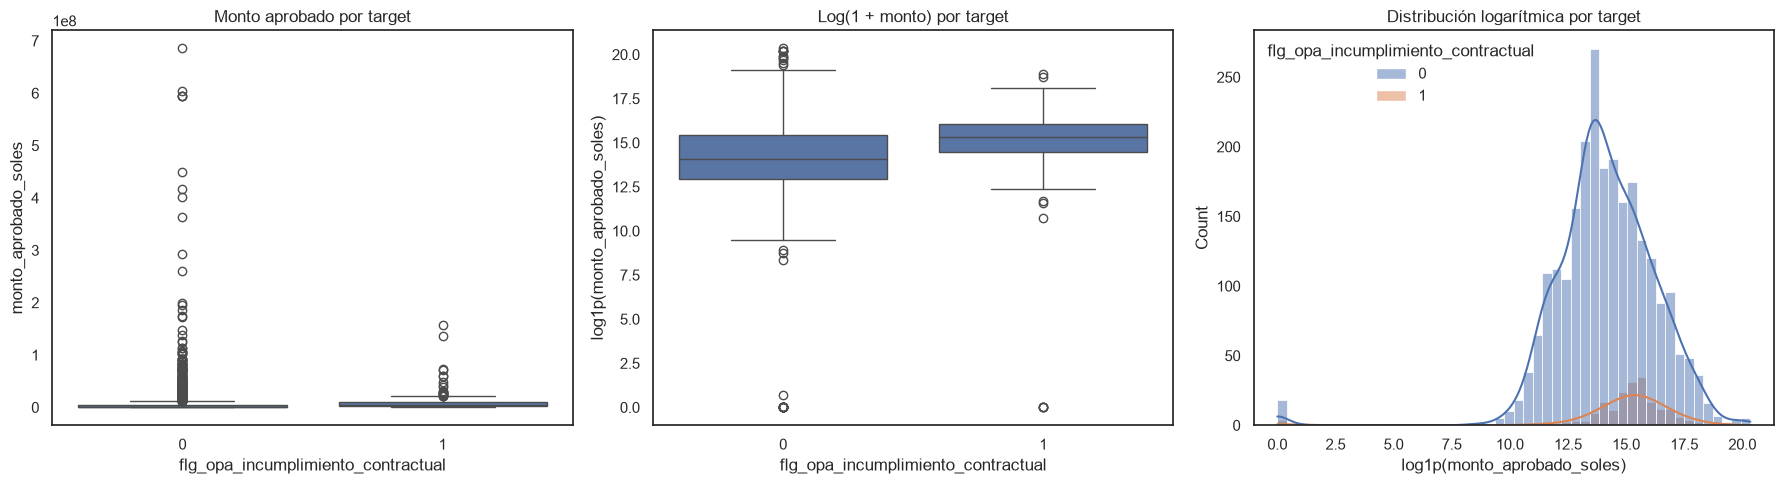

In [24]:
data_outliers, resumen_monto_target = analizar_outliers_monto_vs_target(df_invierte_nacional)

#### 4.3. Transformaciones para outliers

1. Tratar registros con monto_aprobado_soles = 0, reemplazar por el campo monto_aprobado_et
2. Eliminar registro con monto_aprobado_soles = 1 (un caso)
2. Transformación logaritmica log(monto_aprobado_soles)
3. Winsorización de la variable monto_aprobado_soles

##### Analisis y corrección de errores de registros (puntos 1 y 2)

In [25]:
df_invierte_nacional.loc[df_invierte_nacional['monto_aprobado_soles'] ==0, ['monto_aprobado_soles', 'monto_aprobacion_et']]

,monto_aprobado_soles,monto_aprobacion_et
4003,0.0,3.002065e+07
7544,0.0,3.096118e+06
9828,0.0,6.783442e+06
16074,0.0,2.614075e+06
24538,0.0,8.982506e+06
25471,0.0,1.336585e+08
25472,0.0,6.539825e+07
29669,0.0,2.782901e+07
30586,0.0,8.151859e+05
30648,0.0,9.370533e+06


In [26]:
df_invierte_nacional.loc[df_invierte_nacional["monto_aprobado_soles"] == 1, ['monto_aprobado_soles', 'monto_aprobacion_et', 'flg_opa_incumplimiento_contractual']]

,monto_aprobado_soles,monto_aprobacion_et,flg_opa_incumplimiento_contractual
49855,1.0,1.0,0


In [27]:
# Si monto_aprobado_soles == 0, reemplazar por monto_aprobacion_et
df_invierte_nacional.loc[df_invierte_nacional["monto_aprobado_soles"] == 0, "monto_aprobado_soles"] = df_invierte_nacional.loc[
    df_invierte_nacional["monto_aprobado_soles"] == 0, "monto_aprobacion_et"]

In [28]:
# Si monto_aprobado_soles == 1, eliminar el registro
df_invierte_nacional = df_invierte_nacional[df_invierte_nacional["monto_aprobado_soles"] != 1].copy()

=== RESUMEN GENERAL ===
count    2.627000e+03
mean     9.387951e+06
std      3.619776e+07
min      4.316080e+03
1%       3.320584e+04
5%       8.551156e+04
25%      5.007165e+05
50%      1.506341e+06
75%      5.821013e+06
95%      3.889671e+07
99%      1.059563e+08
max      6.854283e+08
Name: monto_aprobado_soles, dtype: float64

=== RESUMEN POR TARGET ===
                                     count          mean           std  \
flg_opa_incumplimiento_contractual                                       
0                                   2430.0  9.352824e+06  3.728421e+07   
1                                    197.0  9.821241e+06  1.809381e+07   

                                         min           1%          5%  \
flg_opa_incumplimiento_contractual                                      
0                                    4316.08   31994.0074   81958.690   
1                                   46059.73  118648.1884  635633.876   

                                           25%     

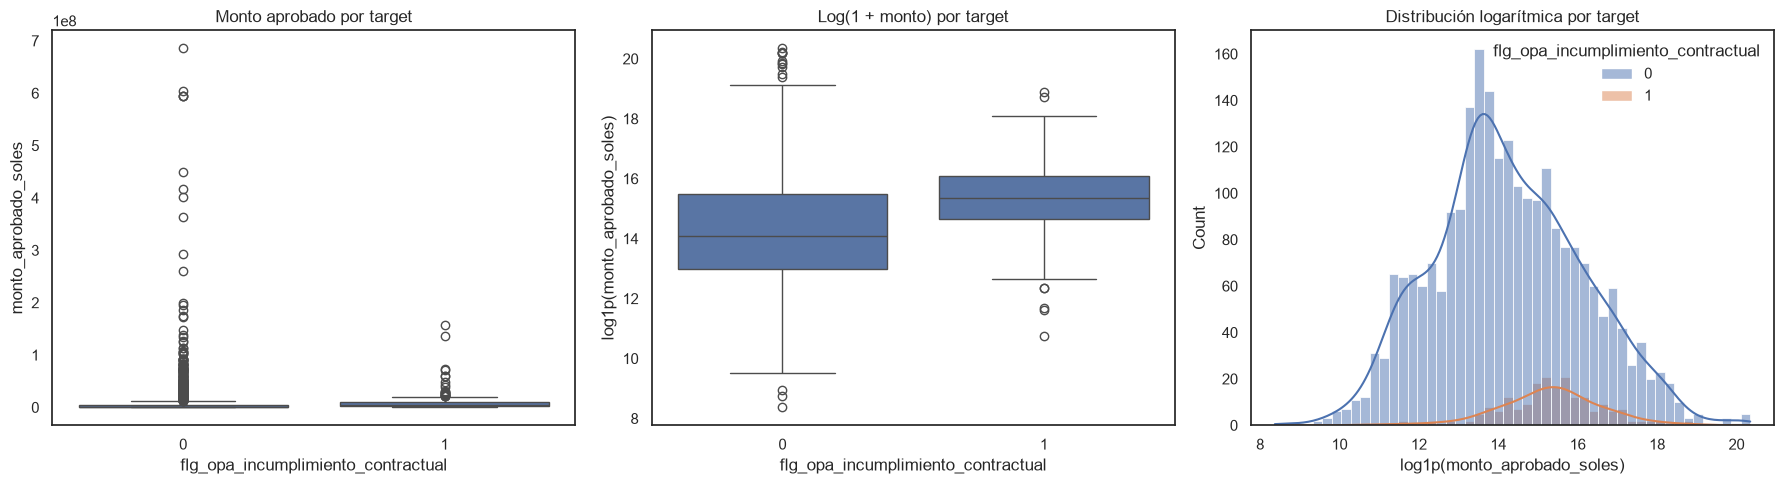

In [29]:
data_outliers_2, resumen_monto_target_2 = analizar_outliers_monto_vs_target(df_invierte_nacional)

##### Nuevas columnas Log y Winzorizada de monto_aprobado_soles

In [30]:
df_invierte_nacional["monto_aprobado_soles_log"] = np.log1p(df_invierte_nacional["monto_aprobado_soles"])

In [31]:
p99 = df_invierte_nacional["monto_aprobado_soles"].quantile(0.99)

df_invierte_nacional["monto_aprobado_soles_winsor_log"] = np.log1p(
    df_invierte_nacional["monto_aprobado_soles"].clip(upper=p99)
)

In [32]:
df_invierte_nacional.groupby('flg_opa_incumplimiento_contractual')[
    ['monto_aprobado_soles_log', 'monto_aprobado_soles_winsor_log']
].describe()

monto_aprobado_soles_log             \
                                                      count       mean   
flg_opa_incumplimiento_contractual                                       
0                                                    2430.0  14.233587   
1                                                     197.0  15.313539   

                                                                               \
                                         std        min        25%        50%   
flg_opa_incumplimiento_contractual                                              
0                                   1.871160   8.370335  12.976663  14.089836   
1                                   1.275999  10.737716  14.661372  15.342362   

                                                          \
                                          75%        max   
flg_opa_incumplimiento_contractual                         
0                                   15.486192  20.345554   
1                                   16.086811  18.874925   

                                   monto_aprobado_soles_winsor_log             \
                                                             count       mean   
flg_opa_incumplimiento_contractual                                              
0                                                           2430.0  14.225276   
1                                                            197.0  15.310259   

                                                                               \
                                         std        min        25%        50%   
flg_opa_incumplimiento_contractual                                              
0                                   1.849245   8.370335  12.976663  14.089836   
1                                   1.267349  10.737716  14.661372  15.342362   

                                                          
                                          75%        max  
flg_opa_incumplimiento_contractual                        
0                                   15.486192  18.478538  
1                                   16.086811  18.478538

### Separación caracteristicas por tipo de dato

In [33]:
# =============================================================================
# 2.4 Listar columnas disponibles por tipo
# =============================================================================

def clasificar_columnas_por_tipo(dataframe):
    """Clasifica columnas según su tipo de dato."""
    cols_numericas = dataframe.select_dtypes(include=[np.number]).columns.tolist()
    cols_categoricas = dataframe.select_dtypes(include=['object', 'category']).columns.tolist()
    cols_datetime = dataframe.select_dtypes(include=['datetime64']).columns.tolist()
    cols_bool = dataframe.select_dtypes(include=['bool']).columns.tolist()
    
    return {
        'numericas': cols_numericas,
        'categoricas': cols_categoricas,
        'datetime': cols_datetime,
        'booleanas': cols_bool
    }

tipos_columnas = clasificar_columnas_por_tipo(df_invierte_nacional)

print("Clasificación de Columnas por Tipo")
print("=" * 60)
for tipo, columnas in tipos_columnas.items():
    print(f"\n{tipo.upper()} ({len(columnas)} columnas):")
    for col in columnas:
        print(f"  - {col}")

Clasificación de Columnas por Tipo

NUMERICAS (12 columnas):
  - n_obras_relacionadas_proyecto
  - codigo_infobras
  - monto_aprobacion_et
  - monto_aprobado_soles
  - tasa_paralizacion_entidad
  - n_obras_x_entidad
  - monto_aprobado_soles_promedio_entidad
  - tasa_paralizacion_departamento
  - tasa_paralizacion_tipo_obra_nivel_1
  - flg_opa_incumplimiento_contractual
  - monto_aprobado_soles_log
  - monto_aprobado_soles_winsor_log

CATEGORICAS (20 columnas):
  - codigo_entidad
  - nivel_gobierno
  - sector_entidad
  - codigo_unico
  - marco
  - tipo_formato
  - des_tipo_formato
  - modalidad_ejecucion_obra
  - estado_ejecucion
  - naturaleza_obra
  - tipo_obra_nivel_1
  - tipo_obra_nivel_2
  - tipo_obra_nivel_3
  - departamento
  - provincia
  - distrito
  - fecha_aprobacion_expediente
  - colegiatura_1
  - colegiatura_2
  - fecha_inicio_obra

DATETIME (0 columnas):

BOOLEANAS (0 columnas):


C:\Users\yanfr\AppData\Local\Temp\ipykernel_16208\1246815510.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_categoricas = dataframe.select_dtypes(include=['object', 'category']).columns.tolist()


In [34]:
df_invierte_nacional[['tasa_paralizacion_entidad']].describe()

,tasa_paralizacion_entidad
count,2627.000000
mean,0.076785
std,0.065284
min,0.000000
25%,0.042110
50%,0.075000
75%,0.102073
max,0.750000


In [35]:
df_invierte_nacional[['naturaleza_obra', 'flg_opa_incumplimiento_contractual']].value_counts(dropna=False, sort=False)

naturaleza_obra        flg_opa_incumplimiento_contractual
Mejoramiento           0                                     553
Remodelación           0                                     181
Rehabilitación         0                                     413
Ampliación             0                                     158
Construcción/Creación  0                                     492
Instalación            0                                     202
Rehabilitación         1                                      83
Recuperación           0                                      22
Renovación             0                                     125
Reparación             0                                     110
Reconstrucción         1                                      20
                       0                                     147
Remodelación           1                                       8
Recuperación           1                                       2
Mejoramiento           1        

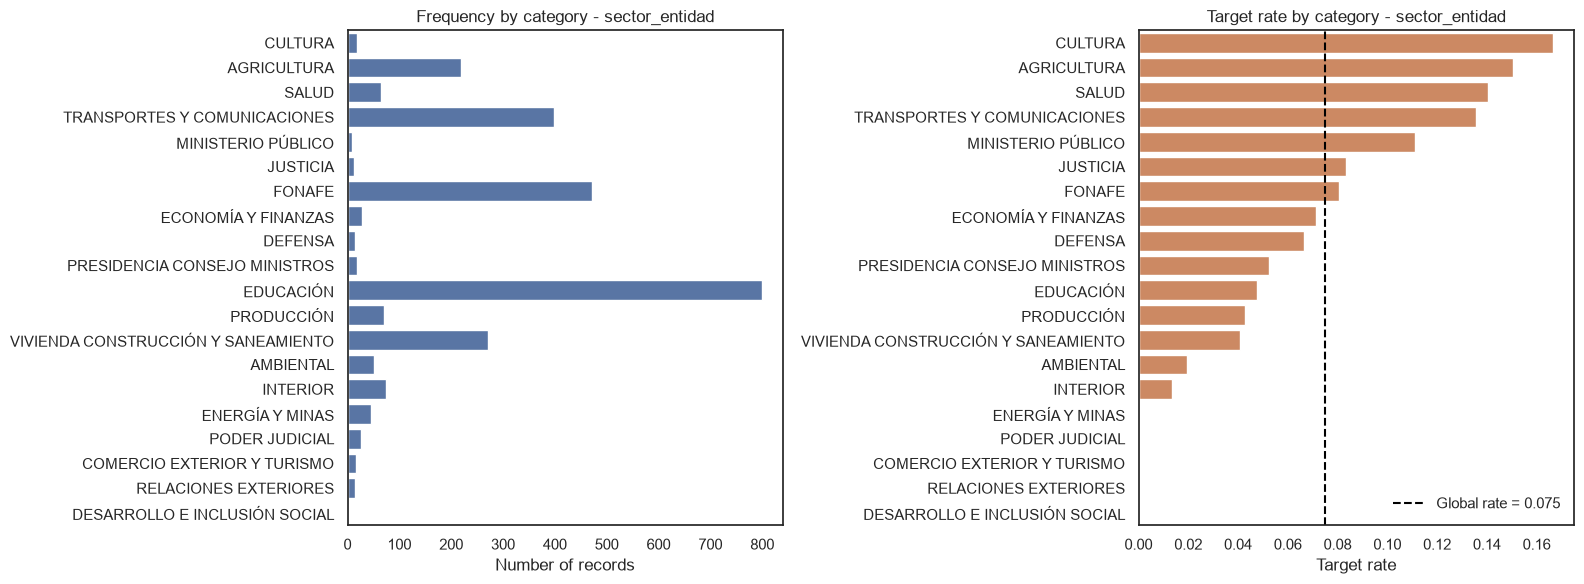

,sector_entidad,count,target_count,target_rate,sample_percentage,lift_vs_global,is_rare_category
0,AGRICULTURA,219,33,0.150685,0.083365,2.009387,False
20,SALUD,64,9,0.140625,0.024362,1.875238,False
21,TRANSPORTES Y COMUNICACIONES,398,54,0.135678,0.151504,1.809275,False
10,FONAFE,471,38,0.080679,0.179292,1.075862,False
7,ECONOMÍA Y FINANZAS,28,2,0.071429,0.010659,0.952502,False
8,EDUCACIÓN,800,38,0.047500,0.304530,0.633414,False
18,PRODUCCIÓN,70,3,0.042857,0.026646,0.571501,False
22,VIVIENDA CONSTRUCCIÓN Y SANEAMIENTO,271,11,0.040590,0.103159,0.541274,False
1,AMBIENTAL,51,1,0.019608,0.019414,0.261471,False
11,INTERIOR,74,1,0.013514,0.028169,0.180203,False


In [43]:
from src.eda import analyze_categorical_vs_target

summary = analyze_categorical_vs_target(
    data=df_invierte_nacional,
    categorical_column="sector_entidad",
    target_column="flg_opa_incumplimiento_contractual",
    min_count=20,
    top_n=20,
)

display(summary)

In [75]:
res_naturaleza.sort_values(by="n")

,departamento,n,n_target_1,tasa_target,porcentaje_muestra,lift_vs_global,categoria_rara
17,NO APLICA,15,0,0.000000,0.005710,0.000000,True
18,P C DEL CALLAO,22,4,0.181818,0.008375,2.424550,False
19,PASCO,24,0,0.000000,0.009136,0.000000,False
15,MADRE DE DIOS,29,4,0.137931,0.011039,1.839314,False
16,MOQUEGUA,37,3,0.081081,0.014085,1.081218,False
23,TACNA,37,1,0.027027,0.014085,0.360406,False
4,AYACUCHO,44,4,0.090909,0.016749,1.212275,False
9,ICA,45,4,0.088889,0.017130,1.185336,False
22,SAN MARTIN,52,1,0.019231,0.019794,0.256443,False
14,LORETO,58,1,0.017241,0.022078,0.229914,False


## Canalización de aprendizaje estadistico

### 1. Separar X e y

In [55]:
from sklearn.model_selection import train_test_split

In [56]:
TARGET = 'flg_opa_incumplimiento_contractual'

df_model = df_invierte_nacional.copy()

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET].astype(int)

### 2. Train, Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [64]:
for col in df_model.columns:
    print(col)

codigo_entidad
nivel_gobierno
sector_entidad
codigo_unico
marco
tipo_formato
des_tipo_formato
n_obras_relacionadas_proyecto
codigo_infobras
modalidad_ejecucion_obra
estado_ejecucion
naturaleza_obra
tipo_obra_nivel_1
tipo_obra_nivel_2
tipo_obra_nivel_3
departamento
provincia
distrito
fecha_aprobacion_expediente
monto_aprobacion_et
monto_aprobado_soles
colegiatura_1
colegiatura_2
tasa_paralizacion_entidad
n_obras_x_entidad
monto_aprobado_soles_promedio_entidad
tasa_paralizacion_departamento
tasa_paralizacion_tipo_obra_nivel_1
flg_opa_incumplimiento_contractual
fecha_inicio_obra
monto_aprobado_soles_log
monto_aprobado_soles_winsor_log


### 3. Definir grupos de columnas

In [ ]:
# Columnas que requieren transformación logaritmica y winsorizacion
amount_log_cols = [
    #"monto_aprobado_soles"
]
# Columnas numericas que requieren estandarización
numeric_standard_cols = [
    #"n_obras_relacionadas_proyecto",
    #"tasa_paralizacion_entidad", # Se debe calcular en Train para evitar el data leakage
    "n_obras_x_entidad",
    #"monto_aprobado_soles_promedio_entidad", # Se debe calcular en Train para evitar el data leakage
    #"tasa_paralizacion_departamento", # Se debe calcular en Train para evitar el data leakage
    #"tasa_paralizacion_tipo_obra_nivel_1", # Se debe calcular en Train para evitar el data leakage
    ### Calculados
    'monto_aprobado_soles_log'
]

categorical_cols = [
    #"nivel_gobierno", #"GOBIERNO NACIONAL"
    "sector_entidad",
    #"marco", # 'INVIERTE'
    "tipo_formato",
    #"des_tipo_formato", # tipo_formato
    #"modalidad_ejecucion_obra", # Un unico valor para el dataset: 'Contrata'
    #"estado_ejecucion",
    "naturaleza_obra",
    "tipo_obra_nivel_1",
    #"tipo_obra_nivel_2",
    #"tipo_obra_nivel_3",
    "departamento",
    #"provincia", # Muy granular
    #"distrito", # Muy granular
    #"colegiatura_2", # No es un buen discriminador
]

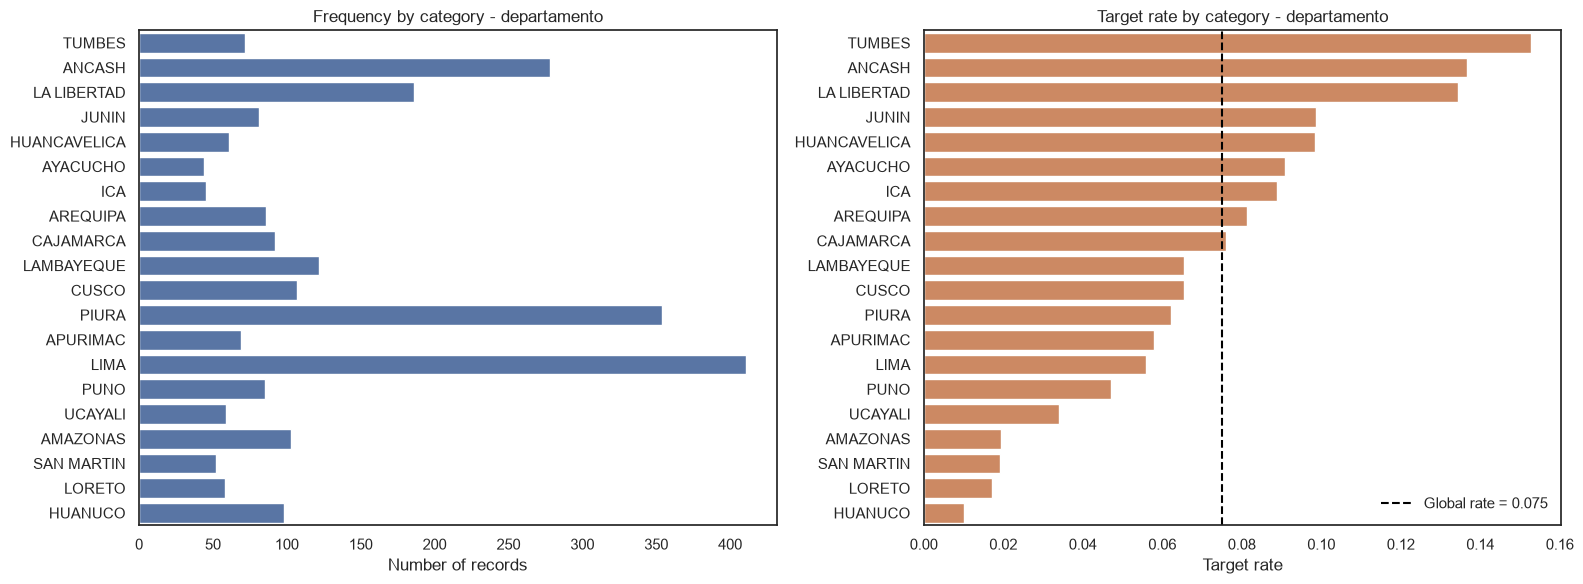

,departamento,count,target_count,target_rate,sample_percentage,lift_vs_global,is_rare_category
18,P C DEL CALLAO,22,4,0.181818,0.008375,2.424550,False
24,TUMBES,72,11,0.152778,0.027408,2.037296,False
15,MADRE DE DIOS,29,4,0.137931,0.011039,1.839314,False
1,ANCASH,278,38,0.136691,0.105824,1.822773,False
11,LA LIBERTAD,186,25,0.134409,0.070803,1.792342,False
10,JUNIN,81,8,0.098765,0.030834,1.317040,False
7,HUANCAVELICA,61,6,0.098361,0.023220,1.311642,False
4,AYACUCHO,44,4,0.090909,0.016749,1.212275,False
9,ICA,45,4,0.088889,0.017130,1.185336,False
3,AREQUIPA,86,7,0.081395,0.032737,1.085409,False


In [82]:
analyze_categorical_vs_target(
    data=df_invierte_nacional,
    categorical_column='departamento',
    target_column='flg_opa_incumplimiento_contractual',
)

### 4. Definir transformadores por grupo

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [101]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin


class WinsorLogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, upper_quantile=0.99):
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X = self._to_dataframe(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.upper_bounds_ = X.quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X = self._to_dataframe(X).copy()
        X = X.clip(upper=self.upper_bounds_, axis=1)
        X = np.log1p(X)

        return pd.DataFrame(
            X,
            columns=self.feature_names_in_,
            index=X.index
        )

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_

        return np.array(
            [f"{col}_winsor_log" for col in input_features],
            dtype=object
        )

    def _to_dataframe(self, X):
        if isinstance(X, pd.DataFrame):
            return X

        return pd.DataFrame(X)

In [85]:
amount_log_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsor_log", WinsorLogTransformer(upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

numeric_standard_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    ))
])

In [86]:
preprocessor = ColumnTransformer(
    transformers=[
        ("amount_log", amount_log_pipeline, amount_log_cols),
        ("numeric_standard", numeric_standard_pipeline, numeric_standard_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

In [92]:
X_train_processed = preprocessor.fit_transform(X_train, y_train)
X_test_processed = preprocessor.transform(X_test)

In [97]:
from scipy import sparse
import joblib

sparse.save_npz("X_train_processed.npz", X_train_processed)
sparse.save_npz("X_test_processed.npz", X_test_processed)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

joblib.dump(preprocessor, "preprocessor.joblib")

['preprocessor.joblib']

In [99]:
feature_names = preprocessor.get_feature_names_out()

pd.Series(feature_names).to_csv(
    "feature_names.csv",
    index=False
)

AttributeError: Estimator winsor_log does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?

In [100]:
X_test_df = pd.DataFrame(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    columns=feature_names
)

X_test_df.to_csv("X_test_processed.csv", index=False)

NameError: name 'feature_names' is not defined

### 5. Definir Pipeline (preprocesamiento + predictor)

In [87]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="saga",
    penalty="l2",
    random_state=42
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

### 6. Entrenamiento (modelo base)

In [88]:
model_pipeline.fit(X_train, y_train)

c:\ws\formacion\uni-mia\mia-tesis-opa\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['codigo_entidad','nivel_gobierno','sector_entidad',..., 'fecha_inicio_obra','monto_aprobado_soles_log', 'monto_aprobado_soles_winsor_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('amount_log', ...), ('numeric_standard', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-spe

### 7. Evaluación (modelo base)

In [89]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [90]:
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

In [91]:
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

ROC AUC: 0.7382193439688306
PR AUC: 0.31172381291481804

Matriz de confusión:
[[344 143]
 [ 15  24]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      0.71      0.81       487
           1       0.14      0.62      0.23        39

    accuracy                           0.70       526
   macro avg       0.55      0.66      0.52       526
weighted avg       0.90      0.70      0.77       526



## Aplicacion de modelo de clasificación

### Cerrar conexión a la BD

In [41]:
# =============================================================================
# Cerrar conexión a la base de datos
# =============================================================================

if pg_conn:
    pg_conn.close()
    print("✓ Conexión a PostgreSQL cerrada")

✓ Conexión a PostgreSQL cerrada
